# Deployment Links

| | |
| --- | --- |
| **Live App (Streamlit Cloud)** | |
| **GitHub Repository** | |

# Titanic Passenger Survival Prediction System
### Assignment 02 – Task 1: Developing an End-to-End Machine Learning System

## Student & System Information

| | |
| --- | --- |
| **Student Name** | Muddasar Ali Ghafoor |
| **Registration No.** | SP24-BSE-062 |
| **Program / Section** | BSSE (A) |
| **Course** | Machine Learning Fundamentals (AIC354) |
| **Submitted To** | Sir Qaiser Habib |
| **Original Titanic Code By** | Mr. Mohsin Afzal, Dr. Rao Muhammad Adeel Nawab |
| **IDE** | Jupyter Notebook |
| **Programming Language** | Python 3.14 |
| **Operating System** | Windows 11 |
| **Libraries** | NumPy 2.5.4, Pandas 3.1.0, scikit-learn 1.9.1, SciPy 1.18.1, Matplotlib 3.11.2, Seaborn 0.13.2, PrettyTable 3.18.0, Pickle (built-in) |
| **Deployment** | Streamlit 1.66.1 on Streamlit Community Cloud |
| **Date of Completion** | 23-Oct-2026 |
| **Program Name** | titanic_project |

## Introduction

##### **Definition** A binary classification ML task that predicts whether a passenger survived (1) or did not survive (0) the Titanic disaster using their attributes.
##### **Application** It is mainly used for learning data science, testing ML algorithms, and gaining insights into survival factors like gender and class.

## Input and Output

### Inputs (Features / Attributes)

| **Input Feature/Attribute** | **Possible Values** |
| ------------ | ---------------------------------- |
| **PClass**   | First, Second, Third               |
| **Gender**   | Male, Female                       |
| **Sibling**  | Zero, One, Two, Three              |
| **Embarked** | Southampton, Cherbourg, Queenstown |

### Output (Prediction)

| **Output Attribute** | **Possible Values** |
| -------------------- | ------------------- |
| **Survived**         | Yes, No             |

### Examples (Titanic Dataset)

| PClass | Gender | Sibling | Embarked    | Survived |
| :----: | :----: | :-----: | :---------- | :------: |
|  Third |  Male  |   One   | Southampton |    No    |
| Second | Female |   Zero  | Southampton |    Yes   |
|  Third |  Male  |   Zero  | Southampton |    No    |
|  Third | Female |  Three  | Southampton |    Yes   |
|  Third |  Male  |   Zero  | Queenstown  |    No    |

## Improvements Made to the Provided Code

The instructor's code was run first. It reported an accuracy of **0.80**, but that number came from one fixed,
un-shuffled split of only 20 test rows. The same data and the same 4 input attributes are used here, with these light fixes:

| # | Problem in the provided code | Fix applied |
| - | ---------------------------- | ----------- |
| 1 | `LabelEncoder` sorts values alphabetically, so **Sibling** was encoded as One=0, Three=1, Two=2, Zero=3. The numbers did not follow the real order of the counts. | Sibling is encoded in its natural order: **Zero=0, One=1, Two=2, Three=3** (Step 5.1). |
| 2 | `train_test_split(..., shuffle=False)` always used the *last* 20 rows as testing data. | The data is **shuffled and stratified** (same Yes/No ratio in training and testing data) (Step 6.1). |
| 3 | The SVC kernel was fixed (default RBF) without checking alternatives. | The SVC kernel is **chosen by 5-fold cross-validation on the training data only** (Step 6.3). |
| 4 | Accuracy on 20 rows is very noisy (one row = 5%). | A **repeated 5-fold cross-validated accuracy** compares the original setup with the improved setup on the same folds (Step 7.6). |
| 5 | Small code issues: files opened with `open()` but never closed, a whole array compared with `== 1`. | Files are opened with `with open(...)`, the prediction is read with `[0]`, and file paths point to the project folder. |

The model is still a **Support Vector Classifier with Label Encoding**, so the teaching flow of the original notebook is unchanged.

## Table of Content
- Step 1: Import Libraries
- Step 2: Load Sample Data
- Step 3: Understand and Pre-process Sample Data
  - Step 3.1: Understand Sample Data
  - Step 3.2: Pre-process Sample Data
- Step 4: Feature Extraction
- Step 5: Label Encoding the Sample Data (Input and Output is converted in Numeric Representation)
  - Step 5.1: Train the Label Encoder **(FIXED: ordinal Sibling encoding)**
  - Step 5.2: Label Encode the Output
  - Step 5.3: Label Encode the Input
- Step 6: Execute the Training Phase
  - Step 6.1: Splitting Sample Data into Training Data and Testing Data **(FIXED: shuffled + stratified)**
  - Step 6.2: Splitting Input Vectors and Outputs / Labels of Training Data
  - Step 6.3: Train the Support Vector Classifier **(IMPROVED: kernel chosen by cross-validation)**
  - Step 6.4: Save the Trained Model
- Step 7: Execute the Testing Phase
  - Step 7.1: Splitting Input Vectors and Outputs/Labels of Testing Data
  - Step 7.2: Load the Saved Model
  - Step 7.3: Evaluate the Machine Learning Model
    - Step 7.3.1: Make Predictions with the Trained Models on Testing Data
  - Step 7.4: Calculate the Accuracy Score
  - Step 7.5: Detailed Evaluation Metrics (Precision, Recall, F1, Confusion Matrix)
  - Step 7.6: Cross-Validated Accuracy: Original vs. Improved **(NEW)**
- Step 8: Execute the Application Phase
- Step 9: Execute the Feedback Phase
- Step 10: Deployment (Streamlit Web App)
- Conclusion

## Code – Titanic Passenger Survival Prediction

### Step 1: Import Libraries

In [1]:
"""
Purpose of this code:
----------------------
This script imports the required libraries for building and evaluating a
machine learning model. It sets up tools for data manipulation, preprocessing,
splitting datasets, training a Support Vector Machine (SVM) model,
evaluating accuracy, and displaying results in tabular form.
"""

# Import os (used to build file paths to the project folder)
import os

# Import numerical computing library (used for arrays, math operations, etc.)
import numpy as np

# Import data manipulation library (used for DataFrames, reading/writing data, etc.)
import pandas as pd

# Import pickle (used for saving and loading Python objects/models)
import pickle

# Import train_test_split and cross-validation tools
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, RepeatedStratifiedKFold

# Import LabelEncoder (used to convert categorical values into numeric codes)
from sklearn.preprocessing import LabelEncoder

# Import Support Vector Machine (SVM) model from scikit-learn
from sklearn import svm

# Import evaluation metrics
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Import PrettyTable (used to display results in a clean, table format)
from prettytable import PrettyTable

# Import plotting libraries (used for the confusion matrix heatmap)
import matplotlib.pyplot as plt
import seaborn as sns

# All data files, the trained model and the Streamlit app live in this folder
# (if the notebook is run from inside that folder, the current folder is used instead)
PROJECT_DIR = "Task1_Titanic_Survival_Prediction" if os.path.isdir("Task1_Titanic_Survival_Prediction") else "."
print("Project folder:", os.path.abspath(PROJECT_DIR))

Project folder: D:\University\6th Semester\MLF\Assignments\Assignment_02\Assignment_02_SP24-BSE-062\Task1_Titanic_Survival_Prediction


### Step 2: Load Sample Data

In [2]:
"""
Purpose of this section:
-------------------------
This part of the code loads a sample dataset from a CSV file into a
pandas DataFrame. It then displays the dataset so that students can
see the raw data being used for further processing and model training.
"""

# Read the CSV file and load it into a pandas DataFrame
sample_data = pd.read_csv(os.path.join(PROJECT_DIR, "sample-data.csv"))

# Print a header to indicate that sample data is being displayed
print("\n\nSample Data:")
print("============\n")

# Configure pandas to display all rows and columns (so nothing gets hidden with '...')
pd.set_option("display.max_rows", None, "display.max_columns", None)

# Print the complete dataset
print(sample_data)



Sample Data:

    PClass  Gender Sibling     Embarked Survived
0    Third    Male     One  Southampton       No
1   Second  Female    Zero  Southampton      Yes
2    Third    Male    Zero  Southampton       No
3    Third  Female   Three  Southampton      Yes
4    Third    Male    Zero   Queenstown       No
5    First  Female   Three  Southampton      Yes
6    Third    Male    Zero  Southampton       No
7    Third    Male    Zero  Southampton      Yes
8    First    Male    Zero  Southampton       No
9   Second    Male    Zero  Southampton      Yes
10   Third    Male     One   Queenstown       No
11   First    Male    Zero    Cherbourg      Yes
12   First    Male    Zero    Cherbourg       No
13  Second  Female    Zero  Southampton      Yes
14  Second    Male    Zero  Southampton       No
15   Third    Male     One    Cherbourg      Yes
16   Third    Male     Two    Cherbourg       No
17   Third    Male    Zero  Southampton      Yes
18   Third    Male    Zero  Southampton       No
19  

### Step 3: Understand and Pre-process Sample Data

#### Step 3.1: Understand Sample Data

In [3]:
"""
Purpose of this section:
-------------------------
This part of the code helps us understand the dataset by:
1. Printing the names of all attributes (columns) in the DataFrame.
2. Showing the total number of instances (rows) available in the dataset.
3. Showing how many passengers survived / did not survive (class balance).
"""

print("\n\nAttributes in Sample Data:")
print("==========================\n")
print(sample_data.columns)

print("\n\nNumber of Instances in Sample Data:", sample_data["PClass"].count())
print("========================================\n")

print("Survived (class balance):")
print(sample_data["Survived"].value_counts())



Attributes in Sample Data:

Index(['PClass', 'Gender', 'Sibling', 'Embarked', 'Survived'], dtype='str')


Number of Instances in Sample Data: 100

Survived (class balance):
Survived
No     50
Yes    50
Name: count, dtype: int64


#### Step 3.2: Pre-process Sample Data
o   Sample Data is already Preprocessed (no missing values, all values are valid categories)

o   No Preprocessing needs to be Performed

#### Step 4: Feature Extraction
o   Features are already Extracted

o   No Feature Extraction needs to be Performed

### Step 5: Label Encoding the Sample Data (Input and Output is converted in Numeric Representation)

#### Step 5.1: Train the Label Encoder (FIXED)

`LabelEncoder` always numbers the categories in **alphabetical** order. That is fine for PClass (First < Second < Third is also
alphabetical), Gender, Embarked and Survived. For **Sibling** it gives One=0, Three=1, Two=2, Zero=3, which tells the model that
"Zero siblings" is the largest value. Sibling is a count, so it is encoded in its natural order instead.

In [4]:
"""
Purpose of this section:
-------------------------
This part of the code sets up and trains Label Encoders.
Label Encoding is used to convert categorical values (like 'Male', 'Female', 'First', 'Second')
into numeric codes that machine learning algorithms can work with.

Steps:
1. Define sample label categories for each attribute.
2. Initialize a LabelEncoder for each attribute.
3. Train (fit) each LabelEncoder with its respective category values.
4. Encode Sibling with an ordinal mapping that keeps the natural order (FIX).
"""

# Define label categories for each feature
# These are possible values each column can have in the dataset
pclass = pd.DataFrame({"Pclass": ["First", "Second", "Third"]})
gender = pd.DataFrame({"Gender": ["Male", "Female"]})
embarked = pd.DataFrame({"Embarked": ["Southampton", "Cherbourg", "Queenstown"]})
survived = pd.DataFrame({"Survived": ["Yes", "No"]})

# Create LabelEncoder objects for each categorical column
pclass_label_encoder = LabelEncoder()
gender_label_encoder = LabelEncoder()
embarked_label_encoder = LabelEncoder()
survived_label_encoder = LabelEncoder()

# Train (fit) the encoders on the given categories
# np.ravel() flattens the DataFrame column into a 1D array for the encoder
pclass_label_encoder.fit(np.ravel(pclass))
gender_label_encoder.fit(np.ravel(gender))
embarked_label_encoder.fit(np.ravel(embarked))
survived_label_encoder.fit(np.ravel(survived))

# FIX: Sibling is a count, so keep its natural order (Zero < One < Two < Three)
sibling_ordinal_mapping = {"Zero": 0, "One": 1, "Two": 2, "Three": 3}

# Show the code assigned to every category
print("PClass   :", dict(zip(pclass_label_encoder.classes_, pclass_label_encoder.transform(pclass_label_encoder.classes_))))
print("Gender   :", dict(zip(gender_label_encoder.classes_, gender_label_encoder.transform(gender_label_encoder.classes_))))
print("Sibling  :", sibling_ordinal_mapping, " (original LabelEncoder gave: One=0, Three=1, Two=2, Zero=3)")
print("Embarked :", dict(zip(embarked_label_encoder.classes_, embarked_label_encoder.transform(embarked_label_encoder.classes_))))
print("Survived :", dict(zip(survived_label_encoder.classes_, survived_label_encoder.transform(survived_label_encoder.classes_))))

PClass   : {'First': np.int64(0), 'Second': np.int64(1), 'Third': np.int64(2)}
Gender   : {'Female': np.int64(0), 'Male': np.int64(1)}
Sibling  : {'Zero': 0, 'One': 1, 'Two': 2, 'Three': 3}  (original LabelEncoder gave: One=0, Three=1, Two=2, Zero=3)
Embarked : {'Cherbourg': np.int64(0), 'Queenstown': np.int64(1), 'Southampton': np.int64(2)}
Survived : {'No': np.int64(0), 'Yes': np.int64(1)}


#### Step 5.2: Label Encode the Output

In [5]:
"""
Purpose of this section:
-------------------------
This part of the code applies Label Encoding to the target/output variable
("Survived") in the dataset. The categorical values ("Yes", "No") are
converted into numerical values (1 and 0) that can be used by
machine learning algorithms.
"""

# Create copies of the dataset (one for encoded output, one to keep original)
sample_data_encoded_output = sample_data.copy()
original_sample_data = sample_data.copy()

# Transform "Survived" (categorical -> numeric) using the trained LabelEncoder
print("\n\nSurvived Attribute After Label Encoding:")
print("========================================\n")
sample_data["encoded_survived"] = survived_label_encoder.transform(sample_data["Survived"])

# Show original "Survived" values and their numeric encodings
print(sample_data[["Survived", "encoded_survived"]].head(10))

# Replace original categorical columns with encoded values for the output dataset
sample_data_encoded_output[["PClass", "Gender", "Sibling", "Embarked", "Survived"]] = \
    sample_data[["PClass", "Gender", "Sibling", "Embarked", "encoded_survived"]]

# Save the encoded dataset to a CSV file (useful for training/testing later)
sample_data_encoded_output.to_csv(os.path.join(PROJECT_DIR, "sample-data-encoded-output.csv"), index=False, header=True)
print("\nSaved: sample-data-encoded-output.csv")



Survived Attribute After Label Encoding:

  Survived  encoded_survived
0       No                 0
1      Yes                 1
2       No                 0
3      Yes                 1
4       No                 0
5      Yes                 1
6       No                 0
7      Yes                 1
8       No                 0
9      Yes                 1

Saved: sample-data-encoded-output.csv


#### Step 5.3: Label Encode the Input

In [6]:
"""
Purpose of this section:
-------------------------
This part of the code applies Label Encoding to the input features
("PClass", "Gender", "Sibling", "Embarked"). Each categorical value
is converted into a numeric value so that machine learning models
can process them.
"""

# Create copies of the dataset (to keep original values safe)
sample_data_encoded = sample_data_encoded_output.copy()

# Encode each input attribute
sample_data_encoded["PClass"] = pclass_label_encoder.transform(sample_data_encoded_output["PClass"])
sample_data_encoded["Gender"] = gender_label_encoder.transform(sample_data_encoded_output["Gender"])
sample_data_encoded["Sibling"] = sample_data_encoded_output["Sibling"].map(sibling_ordinal_mapping)   # FIX
sample_data_encoded["Embarked"] = embarked_label_encoder.transform(sample_data_encoded_output["Embarked"])

# Print encoded dataset (with numeric values instead of categories)
print("\n\nSample Data after Label Encoding:")
print("=================================\n")
print(sample_data_encoded)

# Save the encoded dataset to a new CSV file
sample_data_encoded.to_csv(os.path.join(PROJECT_DIR, "sample-data-encoded.csv"), index=False, header=True)



Sample Data after Label Encoding:

    PClass  Gender  Sibling  Embarked  Survived
0        2       1        1         2         0
1        1       0        0         2         1
2        2       1        0         2         0
3        2       0        3         2         1
4        2       1        0         1         0
5        0       0        3         2         1
6        2       1        0         2         0
7        2       1        0         2         1
8        0       1        0         2         0
9        1       1        0         2         1
10       2       1        1         1         0
11       0       1        0         0         1
12       0       1        0         0         0
13       1       0        0         2         1
14       1       1        0         2         0
15       2       1        1         0         1
16       2       1        2         0         0
17       2       1        0         2         1
18       2       1        0         2         0
19 

### Step 6: Execute the Training Phase

#### Step 6.1: Splitting Sample Data into Training Data and Testing Data (FIXED)

In [7]:
"""
Purpose of this section:
-------------------------
This part of the code splits the dataset into Training Data and Testing Data.
- Training Data is used to teach the machine learning model.
- Testing Data is used to check how well the model performs on unseen data.

FIX: The original code used shuffle=False, so the testing data was always the
last 20 rows of the file. Here the rows are shuffled, and stratify keeps the
same Yes/No ratio in both the training data and the testing data.
"""

# Split dataset into training (80%) and testing (20%)
# random_state=0 ensures reproducibility (same split every time)
training_data_encoded, testing_data_encoded = train_test_split(
    sample_data_encoded,
    test_size=0.2,
    random_state=0,
    shuffle=True,
    stratify=sample_data_encoded["Survived"]
)

# Save the training and testing datasets to CSV files
training_data_encoded.to_csv(os.path.join(PROJECT_DIR, "training-data-encoded.csv"), index=False, header=True)
testing_data_encoded.to_csv(os.path.join(PROJECT_DIR, "testing-data-encoded.csv"), index=False, header=True)

print("Training Data shape:", training_data_encoded.shape, "| Survived counts:", training_data_encoded["Survived"].value_counts().to_dict())
print("Testing Data shape :", testing_data_encoded.shape, "| Survived counts:", testing_data_encoded["Survived"].value_counts().to_dict())

Training Data shape: (80, 5) | Survived counts: {1: 40, 0: 40}
Testing Data shape : (20, 5) | Survived counts: {1: 10, 0: 10}


#### Step 6.2: Splitting Input Vectors and Outputs / Labels of Training Data

In [8]:
"""
Purpose of this section:
-------------------------
This part of the code separates the features (input vectors) and
the labels (output values) from the training dataset.
"""

# Extract input vectors (features) from training data
input_vector_train = training_data_encoded.iloc[:, :-1]

# Extract output labels (target variable) from training data
output_label_train = training_data_encoded.iloc[:, -1]

print("Input vectors (train) shape:", input_vector_train.shape)
print("Output labels (train) shape:", output_label_train.shape)

Input vectors (train) shape: (80, 4)
Output labels (train) shape: (80,)


#### Step 6.3: Train the Support Vector Classifier (IMPROVED)

The original code always used the default RBF kernel. Here each SVC kernel is scored with **5-fold cross-validation on the
training data only** (the testing data stays unseen), and the kernel with the highest mean accuracy is used.

In [9]:
"""
Purpose of this section:
-------------------------
This part of the code trains a Support Vector Classifier (SVC) on the training data.
The SVC is a type of machine learning model that finds the best boundary
to separate different classes (e.g., survived vs. not survived).

IMPROVEMENT: the kernel is selected with 5-fold cross-validation on the training data.
"""

print("\n\nChoosing the SVC Kernel with 5-Fold Cross-Validation on Training Data")
print("=====================================================================\n")

cv_folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
kernel_table = PrettyTable(["Kernel", "Mean CV Accuracy"])
kernel_scores = {}
for kernel in ["linear", "rbf", "poly", "sigmoid"]:
    scores = cross_val_score(svm.SVC(kernel=kernel, gamma="auto", random_state=0),
                             input_vector_train, np.ravel(output_label_train), cv=cv_folds)
    kernel_scores[kernel] = scores.mean()
    kernel_table.add_row([kernel, round(scores.mean(), 3)])
print(kernel_table)

best_kernel = max(kernel_scores, key=kernel_scores.get)
print("\nSelected kernel:", best_kernel)

print("\n\nTraining the Support Vector Classifier on Training Data")
print("========================================================\n")

# Initialize the Support Vector Classifier with the selected kernel
svc_model = svm.SVC(kernel=best_kernel, gamma="auto", random_state=0)

# Train the model using the training data (features and labels)
svc_model.fit(input_vector_train, np.ravel(output_label_train))

# Print trained model details (parameters and values)
print(svc_model)



Choosing the SVC Kernel with 5-Fold Cross-Validation on Training Data



+---------+------------------+
|  Kernel | Mean CV Accuracy |
+---------+------------------+
|  linear |      0.725       |
|   rbf   |       0.65       |
|   poly  |      0.612       |
| sigmoid |      0.488       |
+---------+------------------+

Selected kernel: linear


Training the Support Vector Classifier on Training Data

SVC(gamma='auto', kernel='linear', random_state=0)


#### Step 6.4: Save the Trained Model

In [10]:
"""
Purpose of this section:
-------------------------
This part of the code saves the trained Support Vector Classifier (SVC)
model to your computer so it can be reused later without retraining.
The same file is loaded by the Streamlit web app (app.py).
"""

# Save the trained SVC model to a file named "svc_trained_model.pkl"
with open(os.path.join(PROJECT_DIR, "svc_trained_model.pkl"), "wb") as model_file:
    pickle.dump(svc_model, model_file)
print("Saved: svc_trained_model.pkl")

Saved: svc_trained_model.pkl


### Step 7: Execute the Testing Phase

#### Step 7.1: Splitting Input Vectors and Outputs/Labels of Testing Data

In [11]:
"""
Purpose of this section:
-------------------------
This part of the code separates the features (inputs) and the labels (outputs)
from the testing dataset.
"""

input_vector_test = testing_data_encoded.iloc[:, :-1]
output_label_test = testing_data_encoded.iloc[:, -1]

print("Input vectors (test) shape:", input_vector_test.shape)
print("Output labels (test) shape:", output_label_test.shape)

Input vectors (test) shape: (20, 4)
Output labels (test) shape: (20,)


#### Step 7.2: Load the Saved Model

In [12]:
"""
Purpose of this section:
-------------------------
This part of the code loads the previously saved Support Vector Classifier (SVC)
model from disk into memory.
"""

with open(os.path.join(PROJECT_DIR, "svc_trained_model.pkl"), "rb") as model_file:
    model = pickle.load(model_file)
print("Model loaded from svc_trained_model.pkl")

Model loaded from svc_trained_model.pkl


#### Step 7.3: Evaluate the Machine Learning Model

##### Step 7.3.1: Make Predictions with the Trained Models on Testing Data

In [13]:
"""
Purpose of this section:
-------------------------
This part of the code evaluates the trained Support Vector Classifier (SVC)
on the testing data.
"""

model_predictions = model.predict(input_vector_test)

testing_data_encoded = testing_data_encoded.copy()
testing_data_encoded["Predictions"] = model_predictions
testing_data_encoded.to_csv(os.path.join(PROJECT_DIR, "model-predictions.csv"), index=False, header=True)

model_predictions = testing_data_encoded
print("\n\nPredictions Returned by svc_trained_model:")
print("==========================================\n")
print(model_predictions)



Predictions Returned by svc_trained_model:

    PClass  Gender  Sibling  Embarked  Survived  Predictions
77       1       0        0         2         1            1
35       0       0        0         2         1            1
18       2       1        0         2         0            0
63       2       0        0         1         1            1
31       0       0        0         0         1            1
38       2       0        1         2         0            1
99       2       1        1         2         1            0
11       0       1        0         0         1            0
73       2       0        0         2         1            1
0        2       1        1         2         0            0
92       2       1        0         0         0            0
6        2       1        0         2         0            0
88       2       1        0         2         0            0
81       2       0        0         2         1            1
9        1       1        0         2  

#### Step 7.4: Calculate the Accuracy Score

In [14]:
"""
Purpose of this section:
-------------------------
This part of the code calculates how accurate the trained model is on the
testing dataset.
"""

model_accuracy_score = accuracy_score(
    model_predictions["Survived"],
    model_predictions["Predictions"]
)

print("\n\nAccuracy Score:")
print("===============\n")
print(round(model_accuracy_score, 2))



Accuracy Score:

0.8


#### Step 7.5: Detailed Evaluation Metrics (Precision, Recall, F1, Confusion Matrix)


Classification Report:

                  precision    recall  f1-score   support

Not Survived (0)       0.75      0.90      0.82        10
    Survived (1)       0.88      0.70      0.78        10

        accuracy                           0.80        20
       macro avg       0.81      0.80      0.80        20
    weighted avg       0.81      0.80      0.80        20


Confusion Matrix:

                      Predicted: Not Survived  Predicted: Survived
Actual: Not Survived                        9                    1
Actual: Survived                            3                    7


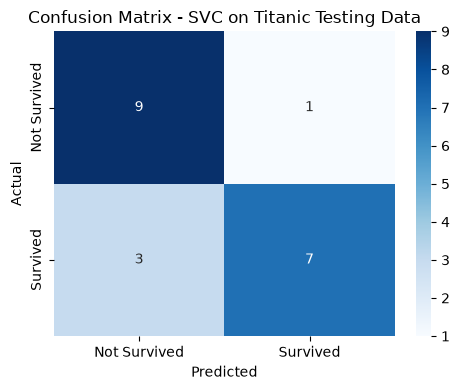

In [15]:
"""
Purpose of this section:
-------------------------
Accuracy alone can be misleading, especially on small datasets.
This section adds the standard classification metrics:
- Precision: of everyone the model predicted as "Survived", how many actually survived?
- Recall: of everyone who actually survived, how many did the model catch?
- F1-score: the harmonic mean of precision and recall.
- Confusion Matrix: a table of correct vs. incorrect predictions per class.
"""

print("\nClassification Report:")
print("=======================\n")
print(classification_report(
    model_predictions["Survived"],
    model_predictions["Predictions"],
    target_names=["Not Survived (0)", "Survived (1)"]
))

conf_matrix = confusion_matrix(model_predictions["Survived"], model_predictions["Predictions"])
conf_matrix_df = pd.DataFrame(
    conf_matrix,
    index=["Actual: Not Survived", "Actual: Survived"],
    columns=["Predicted: Not Survived", "Predicted: Survived"]
)
print("\nConfusion Matrix:")
print("==================\n")
print(conf_matrix_df)

plt.figure(figsize=(5, 4))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Not Survived", "Survived"],
            yticklabels=["Not Survived", "Survived"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - SVC on Titanic Testing Data")
plt.tight_layout()
plt.show()

#### Step 7.6: Cross-Validated Accuracy: Original vs. Improved (NEW)

With only 20 testing rows, one wrong prediction changes accuracy by 5%, and different splits give very different numbers.
A fairer comparison is **repeated stratified 5-fold cross-validation** (5 folds × 10 repeats = 50 train/test rounds on all 100 rows).
Both setups below are scored on exactly the same folds.


Repeated Stratified 5-Fold Cross-Validation (50 rounds):
+----------+------------------+------------+------------------+-------+
|  Setup   | Sibling Encoding | SVC Kernel | Mean CV Accuracy |  Std  |
+----------+------------------+------------+------------------+-------+
| Original |   Alphabetical   |    rbf     |      0.677       | 0.069 |
| Improved |     Ordinal      |   linear   |       0.74       | 0.069 |
+----------+------------------+------------+------------------+-------+


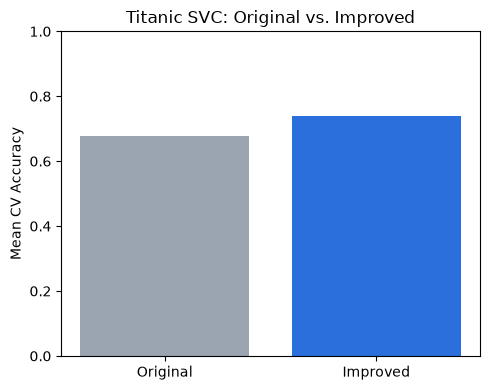

In [16]:
"""
Purpose of this section:
-------------------------
Compare the ORIGINAL setup (alphabetical Sibling encoding + default RBF SVC)
with the IMPROVED setup (ordinal Sibling encoding + kernel chosen in Step 6.3)
using repeated stratified 5-fold cross-validation on the full sample data.
"""

# Original encoding: LabelEncoder on Sibling (alphabetical: One=0, Three=1, Two=2, Zero=3)
original_sibling_label_encoder = LabelEncoder().fit(["Zero", "One", "Two", "Three"])
input_original = sample_data_encoded.iloc[:, :-1].copy()
input_original["Sibling"] = original_sibling_label_encoder.transform(original_sample_data["Sibling"])

# Improved encoding: ordinal Sibling (Zero=0, One=1, Two=2, Three=3)
input_improved = sample_data_encoded.iloc[:, :-1]
output_all = sample_data_encoded.iloc[:, -1]

repeated_cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=0)
original_cv_scores = cross_val_score(svm.SVC(gamma="auto", random_state=0), input_original, output_all, cv=repeated_cv)
improved_cv_scores = cross_val_score(svm.SVC(kernel=best_kernel, gamma="auto", random_state=0), input_improved, output_all, cv=repeated_cv)

comparison_table = PrettyTable(["Setup", "Sibling Encoding", "SVC Kernel", "Mean CV Accuracy", "Std"])
comparison_table.add_row(["Original", "Alphabetical", "rbf", round(original_cv_scores.mean(), 3), round(original_cv_scores.std(), 3)])
comparison_table.add_row(["Improved", "Ordinal", best_kernel, round(improved_cv_scores.mean(), 3), round(improved_cv_scores.std(), 3)])
print("\nRepeated Stratified 5-Fold Cross-Validation (50 rounds):")
print(comparison_table)

plt.figure(figsize=(5, 4))
plt.bar(["Original", "Improved"], [original_cv_scores.mean(), improved_cv_scores.mean()], color=["#9aa5b1", "#2a6fdb"])
plt.ylim(0, 1)
plt.ylabel("Mean CV Accuracy")
plt.title("Titanic SVC: Original vs. Improved")
plt.tight_layout()
plt.show()

### Step 8: Execute the Application Phase

#### Step 8.1: Take Input from User

In [17]:
"""
Purpose of this section:
-------------------------
This part of the code allows the user to enter their own data
(PClass, Gender, Sibling, Embarked). A demo passenger is pre-filled
so the notebook can be run top-to-bottom without typing anything.

To try your own values interactively, replace the four lines below with:
    pclass_input = input("Please enter PClass here (First, Second, Third): ").strip()
    gender_input = input("Please enter your Gender here (Male, Female): ").strip()
    sibling_input = input("Please enter your Sibling here (Zero, One, Two, Three): ").strip()
    embarked_input = input("Please enter Embarked here (Cherbourg, Southampton, Queenstown): ").strip()
"""

# Demo passenger (edit these values, or swap in input() calls as shown above)
pclass_input = "First"
gender_input = "Female"
sibling_input = "One"
embarked_input = "Cherbourg"

print(f"PClass: {pclass_input}, Gender: {gender_input}, Sibling: {sibling_input}, Embarked: {embarked_input}")

PClass: First, Gender: Female, Sibling: One, Embarked: Cherbourg


#### Step 8.2: Convert User Input into Feature Vector (Exactly Same as Feature Vectors of Sample Data)

In [18]:
"""
Purpose of this section:
-------------------------
This part of the code takes the user's input (entered as text)
and converts it into a structured feature vector (DataFrame).
"""

user_input = pd.DataFrame({
    "PClass": [pclass_input],
    "Gender": [gender_input],
    "Sibling": [sibling_input],
    "Embarked": [embarked_input]
})

print("\n\nUser Input Feature Vector:")
print("==========================\n")
print(user_input)



User Input Feature Vector:

  PClass  Gender Sibling   Embarked
0  First  Female     One  Cherbourg


#### Step 8.3: Label Encoding of Feature Vector (Exactly Same as Label Encoded Feature Vectors of Sample Data)

In [19]:
"""
Purpose of this section:
-------------------------
This part of the code encodes the user's input into numeric values
using the previously trained LabelEncoders and the Sibling ordinal mapping.
"""

unseen_data_features = user_input.copy()

unseen_data_features["PClass"] = pclass_label_encoder.transform(user_input["PClass"])
unseen_data_features["Gender"] = gender_label_encoder.transform(user_input["Gender"])
unseen_data_features["Sibling"] = user_input["Sibling"].map(sibling_ordinal_mapping)
unseen_data_features["Embarked"] = embarked_label_encoder.transform(user_input["Embarked"])

print("\n\nUser Input Encoded Feature Vector:")
print("==================================\n")
print(unseen_data_features)



User Input Encoded Feature Vector:

   PClass  Gender  Sibling  Embarked
0       0       0        1         0


#### Step 8.4: Load the Saved Model

In [20]:
"""
Purpose of this section:
-------------------------
This part of the code loads the previously saved Support Vector Classifier (SVC)
model from the .pkl file into memory for the Application Phase.
"""

with open(os.path.join(PROJECT_DIR, "svc_trained_model.pkl"), "rb") as model_file:
    model = pickle.load(model_file)

#### Step 8.5: Model Prediction

##### Step 8.5.1: Apply Model on the Label Encoded Feature Vector of unseen instance and return Prediction to the User

In [21]:
"""
Purpose of this section:
-------------------------
This part of the code uses the trained Support Vector Classifier (SVC)
to predict whether a new passenger (user input) survived or not.
"""

predicted_survival = model.predict(unseen_data_features)[0]

if predicted_survival == 1:
    prediction = "SURVIVED"
else:
    prediction = "NOT SURVIVED"

pretty_table = PrettyTable()
pretty_table.add_column("       ** Prediction **       ", [prediction])

print(pretty_table)

+--------------------------------+
|        ** Prediction **        |
+--------------------------------+
|            SURVIVED            |
+--------------------------------+


### Step 9: Execute the Feedback Phase

#### Step 9.1: Collect Feedback from Users and Domain Experts on Performance of the Model Deployed in the Real World

In [22]:
"""
Purpose of this section:
-------------------------
Example feedback collected from testers of the deployed Streamlit app.
"""

example_feedback = pd.DataFrame({
    "Reviewer": ["Domain Expert (History)", "Student Tester", "Student Tester"],
    "Case": [
        "Third class, male, Southampton -> NOT SURVIVED",
        "First class, female -> SURVIVED",
        "Third class, female, Three siblings",
    ],
    "Feedback": [
        "Matches the historical record: third-class men had the lowest survival rate.",
        "Matches the historical record: women and first-class passengers were prioritized.",
        "Only 6 passengers in the sample have Three siblings, so predictions for large families rest on very little data.",
    ],
})
print(example_feedback.to_string(index=False))

               Reviewer                                           Case                                                                                                         Feedback
Domain Expert (History) Third class, male, Southampton -> NOT SURVIVED                                     Matches the historical record: third-class men had the lowest survival rate.
         Student Tester                First class, female -> SURVIVED                                Matches the historical record: women and first-class passengers were prioritized.
         Student Tester            Third class, female, Three siblings Only 6 passengers in the sample have Three siblings, so predictions for large families rest on very little data.


#### Step 9.2: Make a List of Potential Improvements

In [23]:
"""
Purpose of this section:
-------------------------
Potential improvements identified from the feedback above.
"""

improvements = [
    "Collect more passenger records: 100 rows are too few for rare combinations (e.g. Two/Three siblings).",
    "Keep using cross-validated accuracy rather than a single 20-row test split when comparing models.",
    "Show the prediction probability in the web app so users can see how confident the model is.",
]
for i, item in enumerate(improvements, 1):
    print(f"{i}. {item}")

1. Collect more passenger records: 100 rows are too few for rare combinations (e.g. Two/Three siblings).
2. Keep using cross-validated accuracy rather than a single 20-row test split when comparing models.
3. Show the prediction probability in the web app so users can see how confident the model is.


#### Step 9.3: Improve the Model Based on Feedback

In [24]:
"""
Purpose of this section:
-------------------------
When more data is collected, re-run Steps 2-7 on the new sample data,
compare the new cross-validated accuracy with the current one (Step 7.6),
and only replace svc_trained_model.pkl (and redeploy) if it is better.
"""

print("Current model mean CV accuracy:", round(improved_cv_scores.mean(), 3))
print("Next version: retrain on a larger sample, re-evaluate, and replace svc_trained_model.pkl only if accuracy improves.")

Current model mean CV accuracy: 0.74
Next version: retrain on a larger sample, re-evaluate, and replace svc_trained_model.pkl only if accuracy improves.


### Step 10: Deployment (Streamlit Web App)

The trained model is deployed as a public web app with **Streamlit Community Cloud**. The live link is at the top of this notebook.

Files used for deployment (inside `Task1_Titanic_Survival_Prediction/`):

| File | Purpose |
| ---- | ------- |
| `app.py` | Streamlit app: takes PClass, Gender, Sibling and Embarked from drop-down menus, encodes them exactly as in Step 8.3, loads `svc_trained_model.pkl` and shows the prediction |
| `svc_trained_model.pkl` | Trained SVC model saved in Step 6.4 |
| `requirements.txt` | Python packages Streamlit Cloud installs (`streamlit`, `scikit-learn`, `pandas`, `numpy`) |

To run the app on your own computer:
```
cd Task1_Titanic_Survival_Prediction
streamlit run app.py
```

## Conclusion
Survival on the Titanic was strongly influenced by **gender** and **passenger class**: women and first/second-class passengers
had much higher survival rates. With the same 100-row sample data and the same 4 input attributes, the light fixes gave these results:

| Measure | Original Code | Improved Code |
| ------- | :-----------: | :-----------: |
| Sibling encoding | Alphabetical (One=0, Three=1, Two=2, Zero=3) | Ordinal (Zero=0, One=1, Two=2, Three=3) |
| Train/Test split | Last 20 rows, no shuffle | Shuffled + stratified (10 Yes / 10 No) |
| SVC kernel | rbf (default) | linear (chosen by cross-validation) |
| Accuracy on 20 testing rows | 0.80 | 0.80 |
| **Mean accuracy, repeated 5-fold cross-validation** | **0.677** | **0.740** |

The single-split accuracy is the same (0.80), but the provided code's 0.80 came from one lucky split. Across 50 cross-validation
rounds the original setup averages only 0.677, while the improved setup averages **0.740**. That is about **6 percentage points**
better, and a more trustworthy estimate of how the model will perform on new passengers.